# Projeto de Fusão de Informação em Análises de Dados
---
#### Afonso Rodrigues -- 2020242400 <p>Emanuel Pacheco -- 20_

### Criação dos CSVs para serem utilizados no projeto
#### Professora aconselhou aos dados terem de ser criados por nós, uma vez que não são entregues no enunciado

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [63]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

# Parâmetros da trajetória
theta = np.linspace(np.pi+0.25, -np.pi/2, 100)  # Ângulo de 90° a 360°
radius = 5  # Raio do quase-círculo
center = (0, 0)  # Centro do círculo

# Gerar a trajetória quase-circular
x = radius * np.cos(theta) + center[0]
y = radius * np.sin(theta) + center[1]

# Adicionar observações do GNSS com ruído
y_gnss = np.column_stack((x, y)) + np.random.normal(0, 0.2, (len(x), 2))

# Adicionar estimativa do filtro de Kalman com ruído
x_est = np.column_stack((x, y)) + np.random.normal(0, 0.1, (len(x), 2))

# Gerar matrizes de covariância (exemplo simplificado)
P_est = np.array([np.eye(2) * 0.1 for _ in range(len(x))])

# Função para plotar a trajetória e as elipses de covariância
def plot_trajectory(x, y, y_gnss, x_est, P_est):
    plt.figure(figsize=(10, 8))
    
    # Trajetória verdadeira
    plt.plot(x, y, 'b-', label='Trajetória Verdadeira', linewidth=2)
    
    # Observações do GNSS
    plt.plot(y_gnss[:, 0], y_gnss[:, 1], 'go', label='Observações GNSS', markersize=5, alpha=0.6)
    
    # Estimativa do filtro de Kalman
    plt.plot(x_est[:, 0], x_est[:, 1], 'r-', label='Estimativa do Filtro de Kalman', linewidth=2)
    
    # Elipses de covariância
    for i in range(0, len(x_est), 5):  # Plotar a cada 5 iterações para evitar sobreposição
        cov = P_est[i][:2, :2]  # Submatriz de covariância para x e y
        lambda_, v = np.linalg.eig(cov)
        lambda_ = np.sqrt(lambda_)
        ell = Ellipse(xy=(x_est[i, 0], x_est[i, 1]),
                      width=lambda_[0] * 2, height=lambda_[1] * 2,
                      angle=np.degrees(np.arctan2(v[1, 0], v[0, 0])),
                      edgecolor='red', facecolor='none', linestyle='--')
        plt.gca().add_patch(ell)
    
    plt.xlabel('Posição X')
    plt.ylabel('Posição Y')
    plt.title('Trajetória Quase-Circular do Robô')
    plt.legend()
    plt.grid(True)
    plt.axis('equal')
    plt.show()

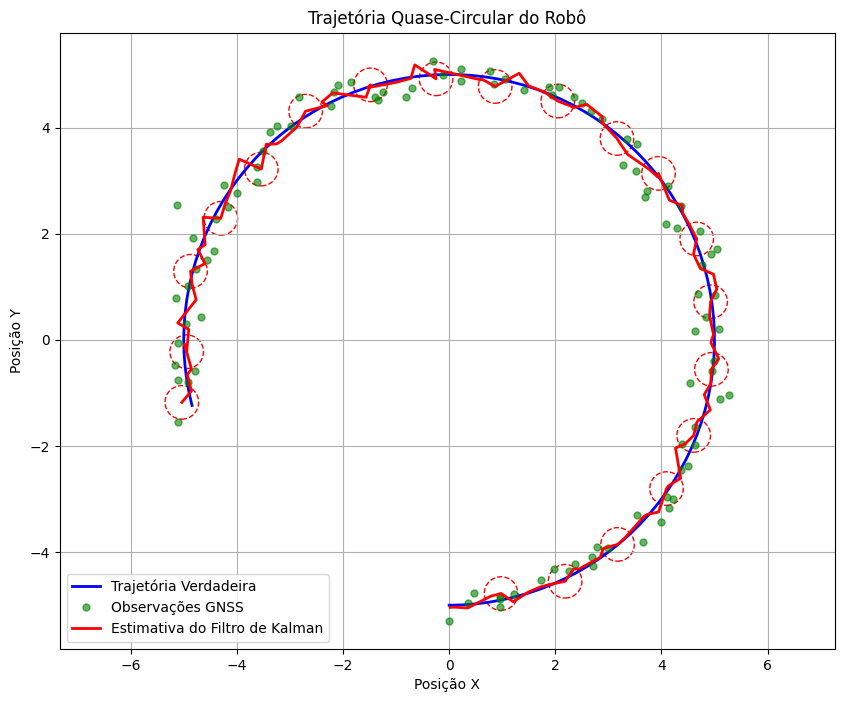

In [64]:
plot_trajectory(x, y, y_gnss, x_est, P_est)

In [ ]:
gnss_data = np.loadtxt("gnss_data.csv", delimiter=",",skiprows=1)
x_gnss = gnss_data[:,0]
y_gnss = gnss_data[:,1]

robot_trajectory = np.loadtxt("robot_trajectory.csv", delimiter=",",skiprows=1)
x_true = robot_trajectory[:,0]
y_true = robot_trajectory[:,1]
orientation = robot_trajectory[:,2]
velocity = robot_trajectory[:,3]

sensor_data = np.loadtxt("sensor_data.csv", delimiter=",",skiprows=1)
x_sensor = sensor_data[:,0]
y_sensor = sensor_data[:,1]
phi_sensor = sensor_data[:,2]
v_sensor = sensor_data[:,3]

# xk = np.a

In [22]:
A = np.array(([1, 0, 0, 0],
             [0, 1, 0, 0],
             [0, 0, 1, 0],
             [0, 0, 0, 0]))

B = 

array([[1, 0, 0, 0],
       [0, 1, 0, 0],
       [0, 0, 1, 0],
       [0, 0, 0, 0]])